# 4.3 Feature Extraction : 3 réseaux pré-entraînés et gelés, Dataset 2 (extrait final, 60 000 images)

Le réseau est gelé : on garde le vecteur qu'il sort pour chaque image et on entraîne une régression
logistique dessus (cours Transfer Learning).

| Réseau | Pré-entraîné sur |
|---|---|
| EfficientNet-B0 (CNN) | ImageNet (photos) |
| DiT-base (Transformer) | IIT-CDIP (documents, sans étiquettes) |
| BEiT-base (Transformer) | ImageNet-22k (photos, sans étiquettes) |

Les vecteurs sont calculés une fois (environ 10 minutes par réseau) puis enregistrés.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")  # avertissement tqdm sans importance

import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from torchvision import models
from transformers import AutoImageProcessor, AutoModel, AutoModelForImageClassification
from transformers.utils import logging

from outils_4 import ARTEFACTS_60K, CLASSES, load_corpus_60k, top_two

logging.disable_progress_bar()
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

train, test = load_corpus_60k()
y_train = train["label"].to_numpy()
y_test = test["label"].to_numpy()

# les 800 documents où le SVM texte hésite le plus (4.2)
scores = pd.read_csv(f"{ARTEFACTS_60K}/scores_svm_60k.csv")
scores_test = scores[scores["ensemble"] == "test"]
ecarts = top_two(scores_test[[f"score_{c}" for c in CLASSES]].to_numpy(), CLASSES)
zone = (ecarts["ecart"] < np.sort(ecarts["ecart"])[799] + 1e-9).to_numpy()
svm_juste = (ecarts["top1"] == y_test).to_numpy()

## 1. Le vecteur produit par un réseau gelé

In [2]:
@torch.no_grad()
def extract_embeddings(nom, chemins, taille_lot=32):
    """le vecteur que sort le réseau gelé pour chaque image"""
    if nom == "efficientnet_b0":
        poids = models.EfficientNet_B0_Weights.IMAGENET1K_V1
        reseau = models.efficientnet_b0(weights=poids).to(device).eval()
        reseau.classifier = torch.nn.Identity()  # sans la dernière couche, il reste un vecteur de 1 280 valeurs
        preparer = lambda images: torch.stack([poids.transforms()(im) for im in images])
        sortie = lambda x: reseau(x)
    else:
        identifiant = {"dit_base": "microsoft/dit-base", "beit_base": "microsoft/beit-base-patch16-224-pt22k"}[nom]
        processeur = AutoImageProcessor.from_pretrained(identifiant)
        reseau = AutoModel.from_pretrained(identifiant).to(device).eval()
        preparer = lambda images: processeur(images=images, return_tensors="pt")["pixel_values"]
        sortie = lambda x: reseau(pixel_values=x).pooler_output
    vecteurs = []
    for debut in range(0, len(chemins), taille_lot):
        images = [Image.open(c).convert("RGB") for c in chemins[debut:debut + taille_lot]]
        vecteurs.append(sortie(preparer(images).to(device)).cpu().numpy())
    return np.concatenate(vecteurs)

## 2. Régression logistique sur les vecteurs de chaque réseau

In [3]:
lignes = [{"modèle": "SVM texte (référence, 4.2)", "accuracy": svm_juste.mean(), "accuracy zone incertaine": svm_juste[zone].mean()}]
predictions = {}
for nom, cle in [("EfficientNet-B0", "efficientnet_b0"), ("DiT-base", "dit_base"), ("BEiT-base", "beit_base")]:
    fichier = f"{ARTEFACTS_60K}/vision_features_{cle}.npz"
    if not os.path.exists(fichier):
        np.savez_compressed(fichier, test_filepaths=test["filepath"].to_numpy(),
                            train_features=extract_embeddings(cle, ["../" + f for f in train["filepath"]]),
                            test_features=extract_embeddings(cle, ["../" + f for f in test["filepath"]]))
    vecteurs = np.load(fichier)
    assert (vecteurs["test_filepaths"] == test["filepath"].to_numpy()).all()

    clf = LogisticRegression(class_weight="balanced", max_iter=5000, random_state=42)
    clf.fit(vecteurs["train_features"], y_train)
    predictions[nom] = clf.predict(vecteurs["test_features"])
    juste = predictions[nom] == y_test
    lignes.append({"modèle": nom, "accuracy": juste.mean(), "accuracy zone incertaine": juste[zone].mean()})

resultats = pd.DataFrame(lignes)
resultats.round(3)

,modèle,accuracy,accuracy zone incertaine
0,"SVM texte (référence, 4.2)",0.867,0.638
1,EfficientNet-B0,0.758,0.596
2,DiT-base,0.761,0.605
3,BEiT-base,0.760,0.610


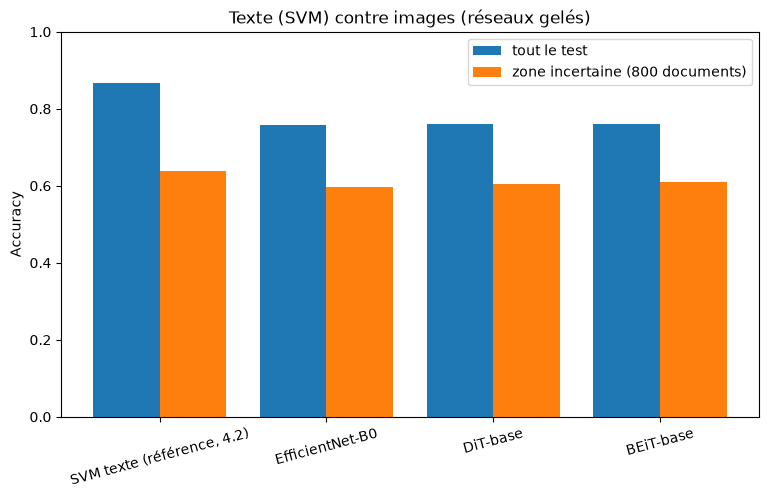

In [4]:
x = np.arange(len(resultats))
plt.figure(figsize=(9, 5))
plt.bar(x - 0.2, resultats["accuracy"], 0.4, label="tout le test")
plt.bar(x + 0.2, resultats["accuracy zone incertaine"], 0.4, label="zone incertaine (800 documents)")
plt.xticks(x, resultats["modèle"], rotation=15)
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Texte (SVM) contre images (réseaux gelés)")
plt.legend()
plt.show()

Les 3 réseaux sont autour de 76 %, loin du texte, mais l'écart se resserre sur les documents où le
texte hésite :

In [5]:
dit_juste = predictions["DiT-base"] == y_test
erreurs_svm = zone & ~svm_juste
print(f"Dans la zone incertaine, le SVM se trompe sur {erreurs_svm.sum()} documents ; "
      f"DiT-base en classe correctement {(erreurs_svm & dit_juste).sum()} ({(erreurs_svm & dit_juste).sum() / erreurs_svm.sum():.0%}).")

Dans la zone incertaine, le SVM se trompe sur 290 documents ; DiT-base en classe correctement 151 (52%).


## 3. Contre-exemple : un modèle qui a déjà vu nos images

Le même DiT, mais déjà entraîné à classer RVL-CDIP sur la partie d'où viennent nos images. Testé tel
quel sur nos 6 classes.

In [6]:
identifiant = "microsoft/dit-base-finetuned-rvlcdip"
processeur = AutoImageProcessor.from_pretrained(identifiant)
dit_rvlcdip = AutoModelForImageClassification.from_pretrained(identifiant).to(device).eval()
numero = {nom.lower().replace(" ", "_"): i for i, nom in dit_rvlcdip.config.id2label.items()}
nos_classes = [numero[c] for c in CLASSES]  # on ne garde que les 6 sorties de nos classes

predictions_dit = []
with torch.no_grad():
    for debut in range(0, len(test), 16):
        images = [Image.open("../" + f).convert("RGB") for f in test["filepath"][debut:debut + 16]]
        logits = dit_rvlcdip(**processeur(images=images, return_tensors="pt").to(device)).logits.cpu().numpy()
        predictions_dit += [CLASSES[i] for i in logits[:, nos_classes].argmax(axis=1)]

print(f"Accuracy de DiT déjà entraîné sur RVL-CDIP : {accuracy_score(y_test, predictions_dit):.1%}")

Accuracy de DiT déjà entraîné sur RVL-CDIP : 98.1%


Le score est très haut mais ne vaut rien : ce modèle a appris avec les étiquettes de nos images de
test (fuite de données).